# 06 · Baseline Marketing Mix Model & control-variable selection
**Team 2 – Marketing Mix Modelling** · Target: `sales_revenue_lkr` (monthly, LKR)

This notebook:
1. Re-checks the data received from Team 1 (`data/processed/mmm_analysis_ready.csv`). These are sanity checks only; cleaning is Team 1's job.
2. Confirms that the chronological train/test split matches Team 1's `split_info.json`.
3. Selects the external factors (controls) for the model, using correlation, VIF and a trend check.
4. Fits the **baseline**: an ordinary least-squares regression on raw spend + controls, without carryover or saturation.

> The baseline is the reference point. Every later model must beat it on hold-out accuracy *and* give more credible channel effects.


In [14]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.mmm_core import *
from src import mmm_plot_style as ps; ps.apply()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG, TAB, MOD = ROOT/"reports/figures", ROOT/"outputs/mmm", ROOT/"models/mmm"
for d in (FIG, TAB, MOD): d.mkdir(parents=True, exist_ok=True)

# ---- Inputs from Team 1 (Data Engineering & EDA) ----
DATA_PATH = ROOT / "data" / "processed" / "mmm_analysis_ready.csv"
SPLIT = json.load(open(ROOT / "data" / "processed" / "split_info.json"))
TRAIN_END = SPLIT["train_end"]   # documented chronological split (train 2023-01..2025-06, test 2025-07..2025-12)
LAB = CHANNEL_LABELS
df = load_data(DATA_PATH)
train, test = df[df.month <= TRAIN_END].reset_index(drop=True), df[df.month > TRAIN_END].reset_index(drop=True)
print(f"{len(df)} months | train {train.month.min():%Y-%m} → {train.month.max():%Y-%m} ({len(train)}) | test {test.month.min():%Y-%m} → {test.month.max():%Y-%m} ({len(test)})")

36 months | train 2023-01 → 2025-06 (30) | test 2025-07 → 2025-12 (6)


## 1. Sanity checks on the input data

In [15]:
checks = {
    "rows": len(df),
    "missing values": int(df.isna().sum().sum()),
    "duplicate months": int(df.month.duplicated().sum()),
    "months contiguous": bool((df.month.diff().dropna().dt.days.between(28, 31)).all()),
    "negative spend": int((df[CHANNELS] < 0).sum().sum()),
    "total_ad_spend = sum of channels": bool(np.allclose(df[CHANNELS].sum(1), df.total_ad_spend_lkr, atol=5)),
}
pd.Series(checks, name="result").to_frame()

,result
rows,36
missing values,22
duplicate months,0
months contiguous,True
negative spend,0
total_ad_spend = sum of channels,True


## 2. Chronological train / test split
Time-series data must not be shuffled. The **last 6 months (Jul–Dec 2025)** are held out as a test set and are never used to choose any model setting. Inside the 30 training months, model settings are chosen with **rolling-origin (expanding-window) cross-validation**: train on months 1…k, predict months k+1…k+3, then move k forward by one month.

In [16]:
assert (len(train), len(test)) == (SPLIT["train_rows"], SPLIT["test_rows"]), "split does not match split_info.json"
assert f"{test.month.min():%Y-%m-%d}" == SPLIT["test_start"]
print("Split matches Team 1's split_info.json ✓")
print("Team 1 walk-forward folds (step 3):", [(f["train_end"], f["validation_start"], f["validation_end"]) for f in SPLIT["walk_forward_folds"]])
print("Model tuning below uses the same origin (18 months) and horizon (3 months), but moves the origin 1 month at a time (10 folds) for a more stable signal.")
folds = pd.DataFrame([{"fold": i+1, "train_months": f"{df.month[tr[0]]:%Y-%m} → {df.month[tr[-1]]:%Y-%m}", "n_train": len(tr),
                       "validate_months": f"{df.month[va[0]]:%Y-%m} → {df.month[va[-1]]:%Y-%m}"}
                      for i, (tr, va) in enumerate(rolling_origin_splits(len(train), 18, 3, 1))])
folds

Split matches Team 1's split_info.json ✓
Team 1 walk-forward folds (step 3): [('2024-06-01', '2024-07-01', '2024-09-01'), ('2024-09-01', '2024-10-01', '2024-12-01'), ('2024-12-01', '2025-01-01', '2025-03-01'), ('2025-03-01', '2025-04-01', '2025-06-01')]
Model tuning below uses the same origin (18 months) and horizon (3 months), but moves the origin 1 month at a time (10 folds) for a more stable signal.


,fold,train_months,n_train,validate_months
0,1,2023-01 → 2024-06,18,2024-07 → 2024-09
1,2,2023-01 → 2024-07,19,2024-08 → 2024-10
2,3,2023-01 → 2024-08,20,2024-09 → 2024-11
3,4,2023-01 → 2024-09,21,2024-10 → 2024-12
4,5,2023-01 → 2024-10,22,2024-11 → 2025-01
5,6,2023-01 → 2024-11,23,2024-12 → 2025-02
6,7,2023-01 → 2024-12,24,2025-01 → 2025-03
7,8,2023-01 → 2025-01,25,2025-02 → 2025-04
8,9,2023-01 → 2025-02,26,2025-03 → 2025-05
9,10,2023-01 → 2025-03,27,2025-04 → 2025-06


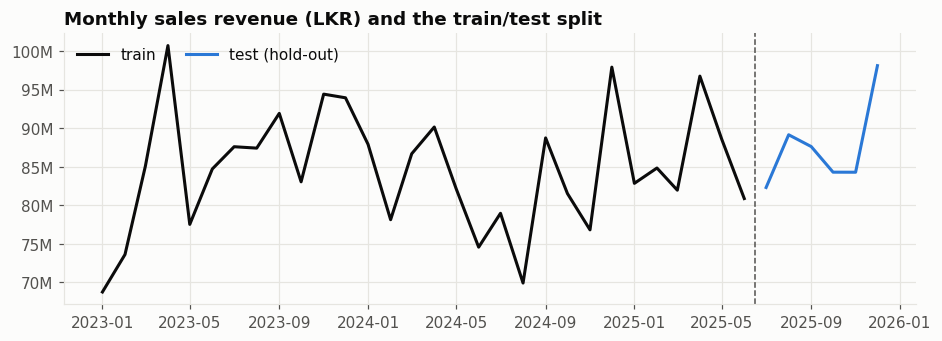

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(train.month, train[TARGET], color=ps.ACTUAL_COLOR, label="train")
ax.plot(test.month, test[TARGET], color=ps.PRED_COLOR, label="test (hold-out)")
ax.axvline(pd.Timestamp(TRAIN_END) + pd.Timedelta(days=15), color=ps.INK2, ls="--", lw=1)
ps.millions(ax); ax.set_title("Monthly sales revenue (LKR) and the train/test split"); ax.legend(loc="upper left", ncol=2)
fig.savefig(FIG / "06_train_test_split.png"); plt.show()

## 3. Spend levels and raw relationships
Raw correlations are a first look only. They mix up the effect of a channel with everything else that moved at the same time (seasonality, promotions, other channels).

In [18]:
summary = pd.DataFrame({
    "avg monthly spend (LKR M)": df[CHANNELS].mean() / 1e6,
    "spend share %": df[CHANNELS].sum() / df[CHANNELS].sum().sum() * 100,
    "coef. of variation": df[CHANNELS].std() / df[CHANNELS].mean(),
    "corr with revenue": df[CHANNELS].corrwith(df[TARGET]),
}).rename(index=LAB)
summary.round(3)

,avg monthly spend (LKR M),spend share %,coef. of variation,corr with revenue
TV,4.360,23.472,0.198,0.325
Facebook/Instagram,4.398,23.678,0.176,0.333
Google Search,3.315,17.847,0.217,0.382
YouTube,2.220,11.950,0.201,0.365
Radio,1.670,8.988,0.163,0.043
Outdoor,2.613,14.065,0.242,0.436


## 4. Selecting external factors (controls)
Candidates from the brief: promotions, holidays, inflation, seasonal demand, economic conditions, competition, price.

Collinear predictors make coefficients unstable, so we check **VIF** (variance inflation factor; > 10 is a problem) and whether there is a **trend** in revenue for trend-like variables to explain.

In [19]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
cand = CHANNELS + ALL_CONTROLS + ["inflation_proxy_index", "lkr_usd_exchange_rate"]
Xv = sm.add_constant(df[cand].assign(time_trend=np.arange(len(df))))
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=Xv.columns[1:], name="VIF")
vif.rename(index=LAB).sort_values(ascending=False).round(1).to_frame()

,VIF
time_trend,970.300
inflation_proxy_index,844.000
average_price_index,107.800
lkr_usd_exchange_rate,7.200
YouTube,3.100
Outdoor,2.900
economic_sentiment_index_0_100,2.800
Google Search,2.700
Radio,2.500
Facebook/Instagram,2.400


In [20]:
yr = df.assign(year=df.month.dt.year).groupby("year").agg(
    revenue_M=(TARGET, lambda s: s.mean()/1e6), units_k=("units_sold", lambda s: s.mean()/1e3),
    price_index=("average_price_index", "mean"), inflation_index=("inflation_proxy_index", "mean"),
    ad_spend_M=("total_ad_spend_lkr", lambda s: s.mean()/1e6))
print("Correlation of price index with inflation index and time:",
      round(df.average_price_index.corr(df.inflation_proxy_index), 3), round(df.average_price_index.corr(pd.Series(np.arange(36))), 3))
yr.round(3)

Correlation of price index with inflation index and time: 0.991 0.993


,revenue_M,units_k,price_index,inflation_index,ad_spend_M
year,,,,,
2023,85.714,158.443,1.033,1.069,19.844
2024,82.774,143.807,1.105,1.236,15.861
2025,86.787,156.676,1.176,1.424,20.024


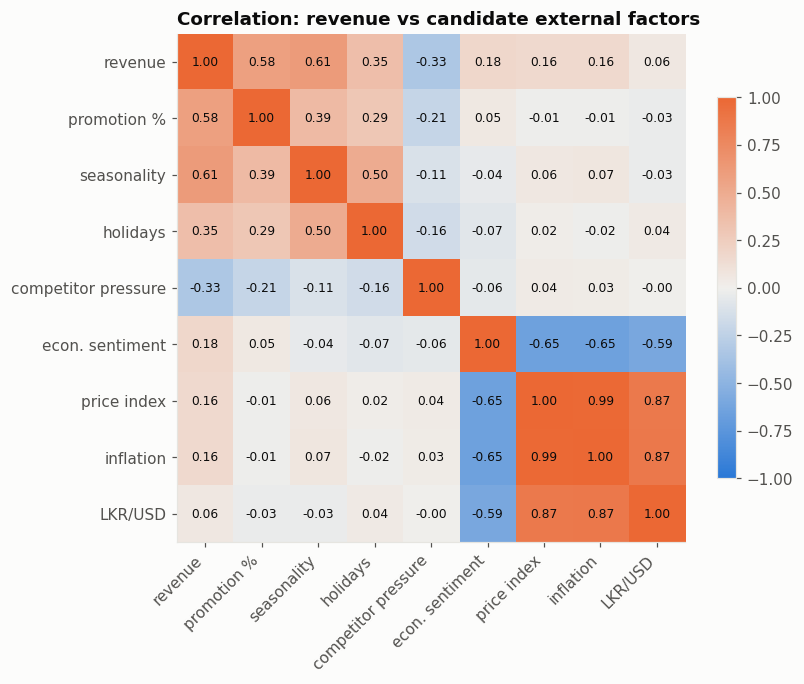

In [21]:
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])
ctrl_cand = ALL_CONTROLS + ["inflation_proxy_index", "lkr_usd_exchange_rate"]
corr = df[[TARGET] + ctrl_cand].corr()
short = {TARGET: "revenue", "promotion_discount_pct": "promotion %", "seasonal_demand_index": "seasonality",
         "public_holiday_count": "holidays", "competitor_pressure_index_0_100": "competitor pressure",
         "economic_sentiment_index_0_100": "econ. sentiment", "average_price_index": "price index",
         "inflation_proxy_index": "inflation", "lkr_usd_exchange_rate": "LKR/USD"}
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.values, cmap=div, vmin=-1, vmax=1)
lbl = [short[c] for c in corr.columns]
ax.set_xticks(range(len(lbl)), lbl, rotation=45, ha="right"); ax.set_yticks(range(len(lbl)), lbl); ax.grid(False)
for i in range(len(lbl)):
    for j in range(len(lbl)):
        ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=8, color=ps.INK)
fig.colorbar(im, ax=ax, shrink=0.75); ax.set_title("Correlation: revenue vs candidate external factors")
fig.savefig(FIG / "06_controls_correlation.png"); plt.show()

In [22]:
# Test the decision with time-aware CV: does adding the trend-like / holiday variables help forecasts?
def ols_cv(controls):
    m = MMM(use_adstock=False, use_saturation=False, nonneg_media=False, controls=controls)
    return cv_rmse(m, train) / 1e6
sets = {"final 4 controls": CONTROLS,
        "+ holidays": CONTROLS + ["public_holiday_count"],
        "+ price index": CONTROLS + ["average_price_index"],
        "+ inflation": CONTROLS + ["inflation_proxy_index"],
        "all 6 candidate controls": ALL_CONTROLS}
pd.Series({k: ols_cv(v) for k, v in sets.items()}, name="CV RMSE (LKR M), lower is better").round(3).to_frame()

,"CV RMSE (LKR M), lower is better"
final 4 controls,6.390
+ holidays,6.810
+ price index,5.744
+ inflation,5.643
all 6 candidate controls,6.379


**Interim decision on controls** (confirmed with the full model in notebook 07):

* **Price index / inflation / exchange rate are kept out of the final model's starting set.** Price and inflation are ~0.99 correlated with each other and with time (VIF in the hundreds), so together they act as a single time trend. Revenue itself has **no trend** (2023: 85.7M, 2024: 82.8M, 2025: 86.8M a month), so whatever the model learns from that "trend" is not interpretable. Adding it lowers plain-OLS CV error a little, but OLS is unconstrained and overfits. Notebook 02 re-tests the price index inside the final constrained model and keeps it only if CV error improves there.
* **Public holiday count is excluded.** Adding it makes CV error worse. The seasonal demand index already includes festive periods.
* **Final starting set:** promotion %, seasonal demand index, competitor pressure, economic sentiment.


## 5. Baseline model — OLS on raw spend + controls
Plain `statsmodels` OLS on the training months. No carryover, no diminishing returns, and coefficients may be negative. A media coefficient here reads as *extra revenue (LKR) per extra LKR spent in the same month*.

In [23]:
def fit_ols(controls):
    X = sm.add_constant(train[CHANNELS + controls]); return sm.OLS(train[TARGET], X).fit()
base_all = fit_ols(ALL_CONTROLS)
base_fin = fit_ols(CONTROLS)
coef = pd.DataFrame({"coef": base_all.params, "std err": base_all.bse, "p-value": base_all.pvalues,
                     "95% low": base_all.conf_int()[0], "95% high": base_all.conf_int()[1]}).rename(index=LAB)
print(f"Baseline OLS (all controls): train R² = {base_all.rsquared:.3f}, adj. R² = {base_all.rsquared_adj:.3f}")
coef.loc[[LAB[c] for c in CHANNELS]].round(3)

Baseline OLS (all controls): train R² = 0.853, adj. R² = 0.750


,coef,std err,p-value,95% low,95% high
TV,1.274,1.356,0.361,-1.587,4.134
Facebook/Instagram,-0.973,1.310,0.468,-3.736,1.790
Google Search,3.942,1.647,0.029,0.467,7.416
YouTube,4.143,2.677,0.140,-1.505,9.791
Radio,-9.027,4.463,0.059,-18.443,0.390
Outdoor,-0.065,1.996,0.974,-4.277,4.146


In [24]:
rows = []
for name, res, ctr in [("Baseline OLS – all controls", base_all, ALL_CONTROLS), ("Baseline OLS – final controls", base_fin, CONTROLS)]:
    p_tr = res.predict(sm.add_constant(train[CHANNELS + ctr]))
    p_te = res.predict(sm.add_constant(test[CHANNELS + ctr], has_constant="add"))
    r = {"model": name, "train R2": res.rsquared, **{f"test {k}": v for k, v in metrics(test[TARGET], p_te).items()}}
    rows.append(r)
base_metrics = pd.DataFrame(rows).set_index("model")
base_metrics.to_csv(TAB / "06_baseline_metrics.csv"); base_metrics.round(3)

,train R2,test RMSE,test MAE,test MAPE_%,test R2
model,,,,,
Baseline OLS – all controls,0.853,"3,480,262.509","2,971,865.346",3.393,0.554
Baseline OLS – final controls,0.821,"4,235,752.630","3,735,057.504",4.289,0.340


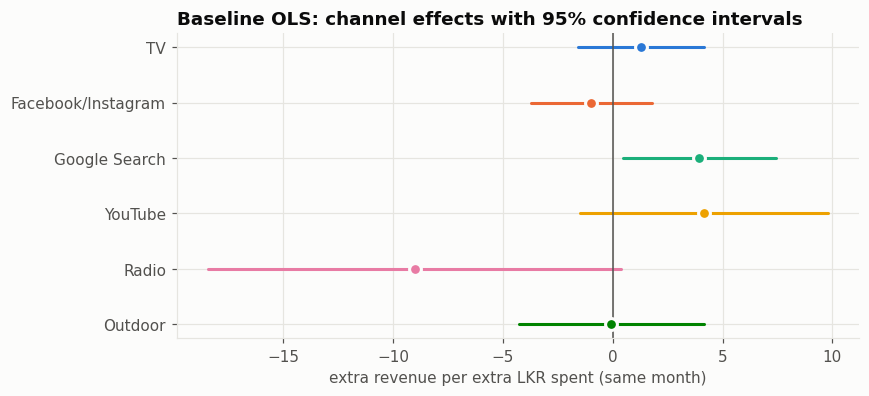

In [25]:
ci = coef.loc[[LAB[c] for c in CHANNELS]]
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(ci))[::-1]
for yi, (name, r) in zip(y, ci.iterrows()):
    col = ps.CHANNEL_COLORS[name]
    ax.plot([r["95% low"], r["95% high"]], [yi, yi], color=col, lw=2, solid_capstyle="round")
    ax.scatter(r["coef"], yi, s=60, color=col, edgecolor=ps.SURFACE, linewidth=2, zorder=3)
ax.axvline(0, color=ps.INK2, lw=1)
ax.set_yticks(y, ci.index); ax.set_xlabel("extra revenue per extra LKR spent (same month)")
ax.set_title("Baseline OLS: channel effects with 95% confidence intervals")
fig.savefig(FIG / "06_baseline_coefficients.png"); plt.show()

### What the baseline tells us
* The model explains revenue well **in-sample** but most channel intervals are very wide and cross zero, because 30 months is not enough to separate six correlated channels.
* **Radio gets a large negative coefficient** (about −9 LKR per LKR, p ≈ 0.06). Advertising cannot plausibly *reduce* sales, so this is a sign of overfitting or confounding, not a real effect. This motivates the final model's design:
  1. **non-negative media coefficients**
  2. **adstock**, so the effect of spend can carry into later months
  3. **saturation**, so returns diminish as spend grows
  4. **ridge regularisation**, so effects are not split unstably across correlated channels


In [26]:
import joblib
joblib.dump({"all_controls": base_all, "final_controls": base_fin}, MOD / "baseline_ols.pkl")
coef.to_csv(TAB / "06_baseline_coefficients.csv")
print("saved: baseline_ols.pkl, 01_baseline_coefficients.csv, 01_baseline_metrics.csv, train_test_split.csv")

saved: baseline_ols.pkl, 01_baseline_coefficients.csv, 01_baseline_metrics.csv, train_test_split.csv
